# Clustering Case Study: Customer Segmentation with K-Means -  Tier 3
***
This case study is based on [this blog post](http://blog.yhat.com/posts/customer-segmentation-using-python.html) by the `yhat` blog. Please feel free to refer to the post for additional information, and solutions.

Structure of the mini-project:

1. **Sourcing and loading**
    * Load the data
    * Explore the data


2. **Cleaning, transforming and visualizing**
    * Data Wrangling: Exercise Set 1
        - Creating a matrix with a binary indicator for whether they responded to a given offer
        - Ensure that in doing so, NAN values are dealt with appropriately
    

3. **Modelling** 
    * K-Means clustering: Exercise Sets 2 and 3
        - Choosing K: The Elbow method
        - Choosing K: The Silhouette method
        - Choosing K: The Gap statistic method
    
    * Visualizing clusters with PCA: Exercise Sets 4 and 5


4. **Conclusions and next steps**
    * Conclusions
    * Other clustering algorithms (Exercise Set 6)

In [1]:
%matplotlib inline
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import numpy as np

# Setup Seaborn
sns.set_style("whitegrid")
sns.set_context("poster")

## 1. Sourcing and loading
### 1a. Load the data
The dataset contains information on marketing newsletters/e-mail campaigns (e-mail offers sent to customers) and transaction level data from customers. The transactional data shows which offer customers responded to, and what the customer ended up buying. The data is presented as an Excel workbook containing two worksheets. Each worksheet contains a different dataset.

In [2]:
df_offers = pd.read_excel("WineKMC.xlsx", sheet_name=0)

C:\Users\parva\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


In [3]:
df_offers.shape

(32, 7)

In [4]:
df_offers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Offer #           32 non-null     int64 
 1   Campaign          32 non-null     object
 2   Varietal          32 non-null     object
 3   Minimum Qty (kg)  32 non-null     int64 
 4   Discount (%)      32 non-null     int64 
 5   Origin            32 non-null     object
 6   Past Peak         32 non-null     bool  
dtypes: bool(1), int64(3), object(3)
memory usage: 1.7+ KB


In [5]:
df_offers.describe()

,Offer #,Minimum Qty (kg),Discount (%)
count,32.000000,32.000000,32.000000
mean,16.500000,65.812500,57.843750
std,9.380832,50.785722,20.770807
min,1.000000,6.000000,17.000000
25%,8.750000,12.000000,44.750000
50%,16.500000,72.000000,55.000000
75%,24.250000,72.000000,82.250000
max,32.000000,144.000000,89.000000


### 1b. Explore the data

In [6]:
df_offers.columns = ["offer_id", "campaign", "varietal", "min_qty", "discount", "origin", "past_peak"]
df_offers.head()

,offer_id,campaign,varietal,min_qty,discount,origin,past_peak
0,1,January,Malbec,72,56,France,False
1,2,January,Pinot Noir,72,17,France,False
2,3,February,Espumante,144,32,Oregon,True
3,4,February,Champagne,72,48,France,True
4,5,February,Cabernet Sauvignon,144,44,New Zealand,True


We see that the first dataset contains information about each offer such as the month it is in effect and several attributes about the wine that the offer refers to: the variety, minimum quantity, discount, country of origin and whether or not it is past peak. The second dataset in the second worksheet contains transactional data -- which offer each customer responded to.

In [7]:
df_transactions = pd.read_excel("WineKMC.xlsx", sheet_name=1)
df_transactions.columns = ["customer_name", "offer_id"]
df_transactions['n'] = 1
df_transactions.head()

C:\Users\parva\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


,customer_name,offer_id,n
0,Smith,2,1
1,Smith,24,1
2,Johnson,17,1
3,Johnson,24,1
4,Johnson,26,1


## 2. Cleaning, transforming and visualizing
### 2a. Data Wrangling

We're trying to learn more about how our customers behave, so we can use their behavior (whether or not they purchased something based on an offer) as a way to group similar minded customers together. We can then study those groups to look for patterns and trends which can help us formulate future offers.

The first thing we need is a way to compare customers. To do this, we're going to create a matrix that contains each customer and a 0/1 indicator for whether or not they responded to a given offer. 

<div class="span5 alert alert-info">
<h3>Checkup Exercise Set I</h3>

<p><b>Exercise:</b> Create a data frame where each row has the following columns (Use the pandas [`merge`](http://pandas.pydata.org/pandas-docs/stable/generated/pandas.DataFrame.merge.html) and [`pivot_table`](http://pandas.pydata.org/pandas-docs/stable/generated/pandas.pivot_table.html) functions for this purpose):
<ul>
<li> customer_name
<li> One column for each offer, with a 1 if the customer responded to the offer
</ul>
<p>Make sure you also deal with any weird values such as `NaN`. Read the documentation to develop your solution.</p>
</div>

In [8]:
#your turn
merged = pd.merge(df_transactions, df_offers)
pivoted = merged.pivot_table(index='customer_name', columns='offer_id', values='n', fill_value=0).astype(int)
pivoted

offer_id,1,2,3,4,5,6,7,8,9,10,...,23,24,25,26,27,28,29,30,31,32
customer_name,,,,,,,,,,,,,,,,,,,,,
Adams,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,0
Allen,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
Anderson,0,0,0,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,0,0
Bailey,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
Baker,0,0,0,0,0,0,1,0,0,1,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Williams,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
Wilson,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
Wood,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0


In [9]:
pivoted.isnull().sum()

offer_id
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
21    0
22    0
23    0
24    0
25    0
26    0
27    0
28    0
29    0
30    0
31    0
32    0
dtype: int64

## 3. Modelling 
### 3a. K-Means Clustering

Recall that in K-Means Clustering we want to *maximize* the distance between centroids and *minimize* the distance between data points and the respective centroid for the cluster they are in. True evaluation for unsupervised learning would require labeled data; however, we can use a variety of intuitive metrics to try to pick the number of clusters K. We will introduce two methods: the Elbow method, the Silhouette method and the gap statistic.

#### 3ai. Choosing K: The Elbow Sum-of-Squares Method

The first method looks at the sum-of-squares error in each cluster against $K$. We compute the distance from each data point to the center of the cluster (centroid) to which the data point was assigned. 

$$SS = \sum_k \sum_{x_i \in C_k} \sum_{x_j \in C_k} \left( x_i - x_j \right)^2 = \sum_k \sum_{x_i \in C_k} \left( x_i - \mu_k \right)^2$$

where $x_i$ is a point, $C_k$ represents cluster $k$ and $\mu_k$ is the centroid for cluster $k$. We can plot SS vs. $K$ and choose the *elbow point* in the plot as the best value for $K$. The elbow point is the point at which the plot starts descending much more slowly. 

**Hint:** the Elbow Method is discussed in part 2 of the Harvard Clustering lecture. 

<div class="span5 alert alert-info">
<h3>Checkup Exercise Set II</h3>

<p><b>Exercise:</b></p> 
<ul>
<li> What values of $SS$ do you believe represent better clusterings? Why?
<li> Create a numpy matrix `x_cols` with only the columns representing the offers (i.e. the 0/1 colums) 
<li> Write code that applies the [`KMeans`](http://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) clustering method from scikit-learn to this matrix. 
<li> Construct a plot showing $SS$ for each $K$ and pick $K$ using this plot. For simplicity, test $2 \le K \le 10$.
<li> Make a bar chart showing the number of points in each cluster for k-means under the best $K$.
<li> What challenges did you experience using the Elbow method to pick $K$?
</ul>
</div>

C:\Users\parva\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\parva\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\parva\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\parva\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

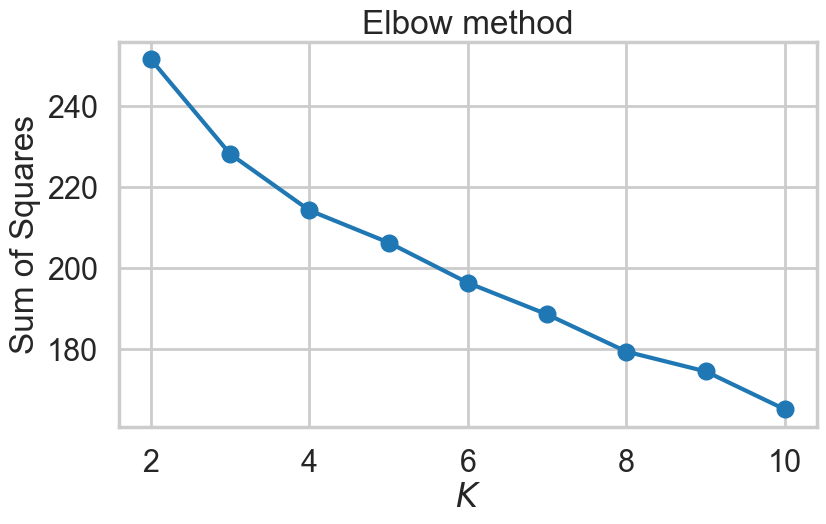

K,2,3,4,5,6,7,8,9,10
SS,251.5,228.2,214.3,206.3,196.4,188.6,179.4,174.5,165.1


In [10]:
# your turn
import sklearn.cluster

SEED = 42   

# Make an empty list
ss = []

# Make an empty dictionary called assignments
assignments = {}

# Cast your table 'pivoted' as a matrix with to_numpy(), and store it in a variable X
X = pivoted.to_numpy()

# Make a variable called Krange, and assign it a list of range(2, 11)
Krange = list(range(2, 11))

# We now want to iterate through this list to construct a plot showing SS for each K. Name the iterator variable K
for K in Krange:
    # Make a variable called model, and assign it the result of calling sklearn.cluster.KMeans, with n_clusters = K
    # n_init=10 runs 10 random starts and keeps the best one, so results are stable
    model = sklearn.cluster.KMeans(n_clusters=K, random_state=SEED, n_init=10)
    assigned_cluster = model.fit_predict(X)
    ss.append(model.inertia_)   # inertia_ is exactly the within-cluster sum of squares
    assignments[str(K)] = assigned_cluster

# Call plot() on plt with parameters Krange and ss
plt.figure(figsize=(9, 5))
plt.plot(Krange, ss, marker='o')

# Let's label the plot
plt.xlabel("$K$")
plt.ylabel("Sum of Squares")
plt.title("Elbow method")
plt.show()

pd.DataFrame({"K": Krange, "SS": np.round(ss, 1)}).set_index("K").T

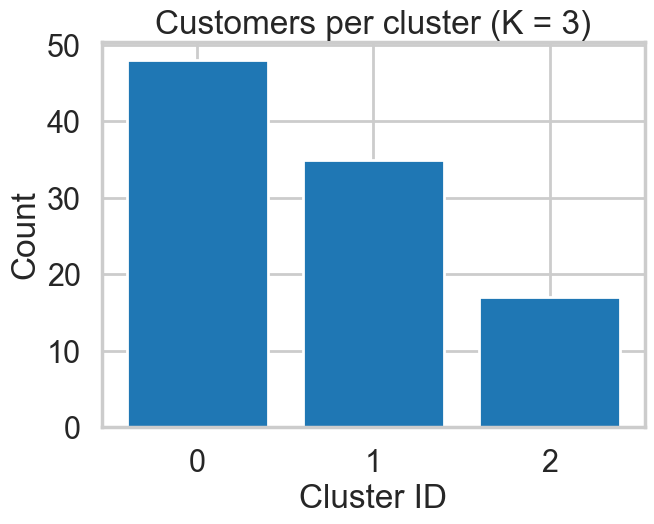

array([48, 35, 17])

In [11]:
best_K = 3
assignments_best_K = assignments[str(best_K)]
counts = np.bincount(assignments_best_K)

# Call bar() on plt, with parameters range(best_K), counts, and align = 'center'
plt.figure(figsize=(7, 5))
plt.bar(range(best_K), counts, align='center')

# Label the axes
plt.xlabel("Cluster ID")
plt.ylabel("Count")
plt.title(f"Customers per cluster (K = {best_K})")
plt.xticks(range(best_K))
plt.show()
counts

- **Which SS values are better?** A lower SS means points sit closer to their centroids, so the clusters are tighter. But SS *always* falls as K rises (with K = 100 each customer is its own cluster and SS = 0). So we don't just minimise SS. We look for the K after which adding clusters stops buying much reduction: the elbow.
- **Choice of K:** SS drops about 23 going from K = 2 to K = 3 (251.5 to 228.2). After that it falls almost linearly, about 5–14 per extra cluster. The elbow is at **K = 3**.
- **Challenges:** the curve is smooth, with no sharp kink, so picking the elbow is subjective. The result also depends on KMeans' random initialisation. With a single random start (the old default), the curve changed between runs, which is why `n_init=10` and a fixed seed are used here.

#### 3aii. Choosing K: The Silhouette Method

There exists another method that measures how well each datapoint $x_i$ "fits" its assigned cluster *and also* how poorly it fits into other clusters. This is a different way of looking at the same objective. Denote $a_{x_i}$ as the *average* distance from $x_i$ to all other points within its own cluster $k$. The lower the value, the better. On the other hand $b_{x_i}$ is the minimum average distance from $x_i$ to points in a different cluster, minimized over clusters. That is, compute separately for each cluster the average distance from $x_i$ to the points within that cluster, and then take the minimum. The silhouette $s(x_i)$ is defined as

$$s(x_i) = \frac{b_{x_i} - a_{x_i}}{\max{\left( a_{x_i}, b_{x_i}\right)}}$$

The silhouette score is computed on *every datapoint in every cluster*. The silhouette score ranges from -1 (a poor clustering) to +1 (a very dense clustering) with 0 denoting the situation where clusters overlap. Some criteria for the silhouette coefficient is provided in the table below.

<pre>

| Range       | Interpretation                                |
|-------------|-----------------------------------------------|
| 0.71 - 1.0  | A strong structure has been found.            |
| 0.51 - 0.7  | A reasonable structure has been found.        |
| 0.26 - 0.5  | The structure is weak and could be artificial.|
| < 0.25      | No substantial structure has been found.      |

</pre>
Source: http://www.stat.berkeley.edu/~spector/s133/Clus.html

**Hint**: Scikit-learn provides a function to compute this for us (phew!) called [`sklearn.metrics.silhouette_score`](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html). Take a look at [this article](http://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html) on picking $K$ in scikit-learn, as it will help you in the next exercise set.

<div class="span5 alert alert-info">
<h3>Checkup Exercise Set III</h3>

<p><b>Exercise:</b> Using the documentation for the `silhouette_score` function above, construct a series of silhouette plots like the ones in the article linked above.</p>

<p><b>Exercise:</b> Compute the average silhouette score for each $K$ and plot it. What $K$ does the plot suggest we should choose? Does it differ from what we found using the Elbow method?</p>
</div>

C:\Users\parva\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


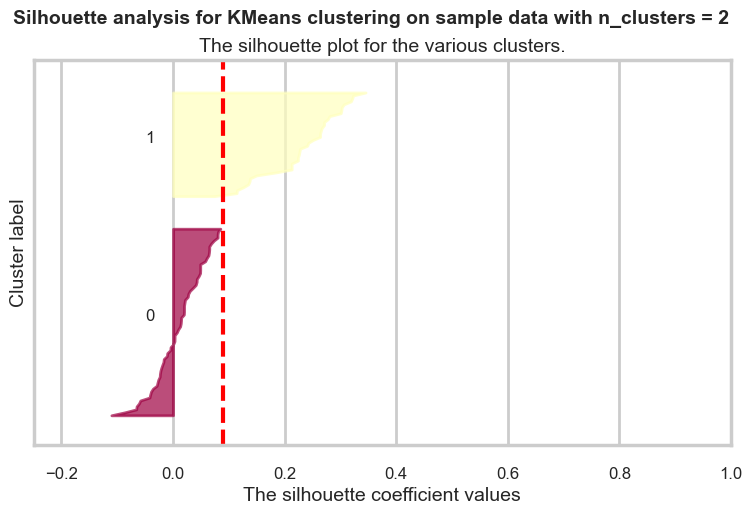

C:\Users\parva\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


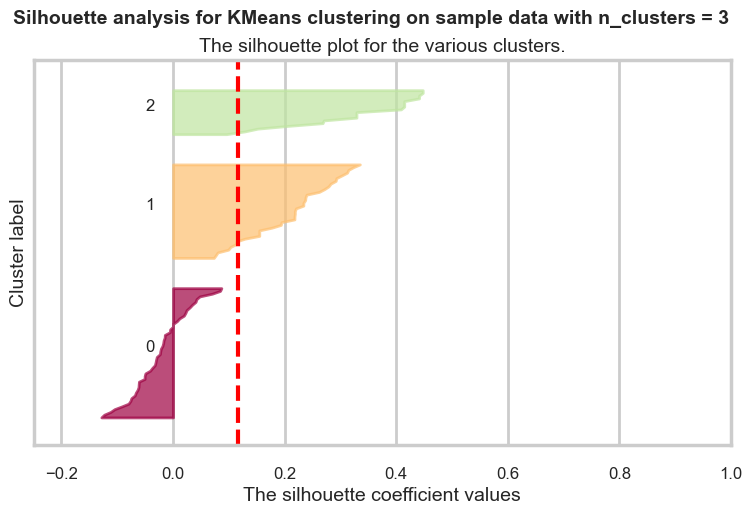

C:\Users\parva\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


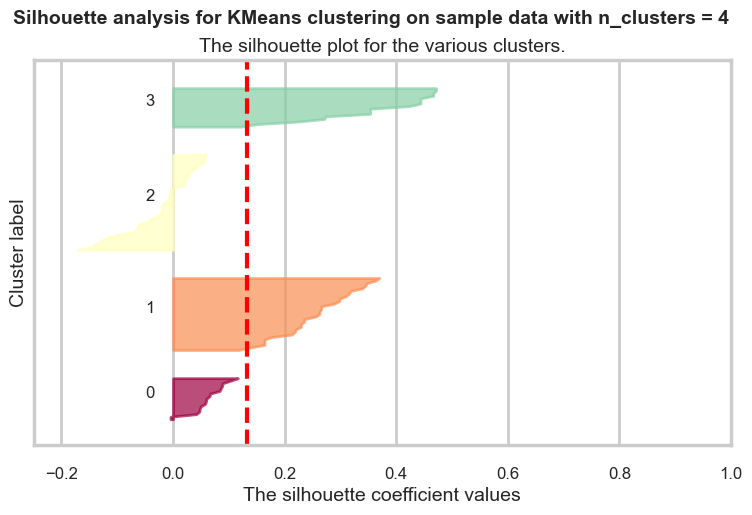

C:\Users\parva\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


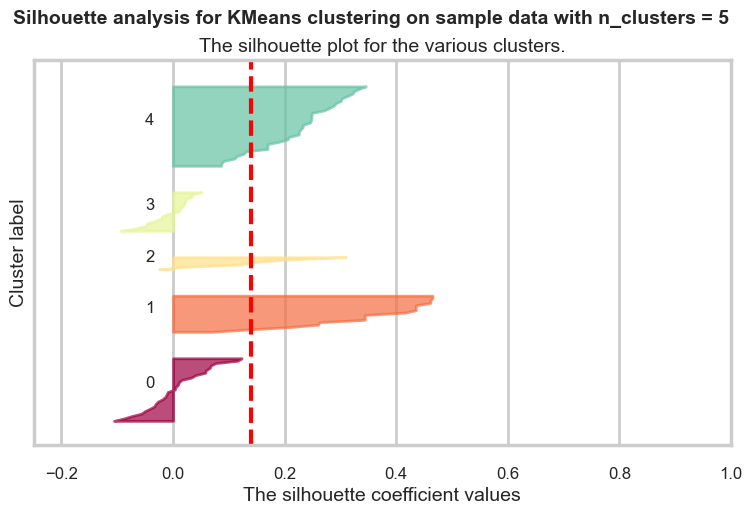

C:\Users\parva\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


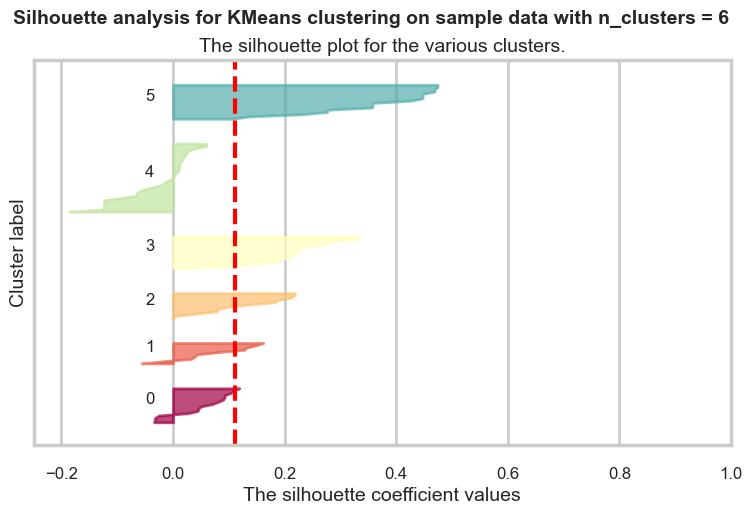

C:\Users\parva\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


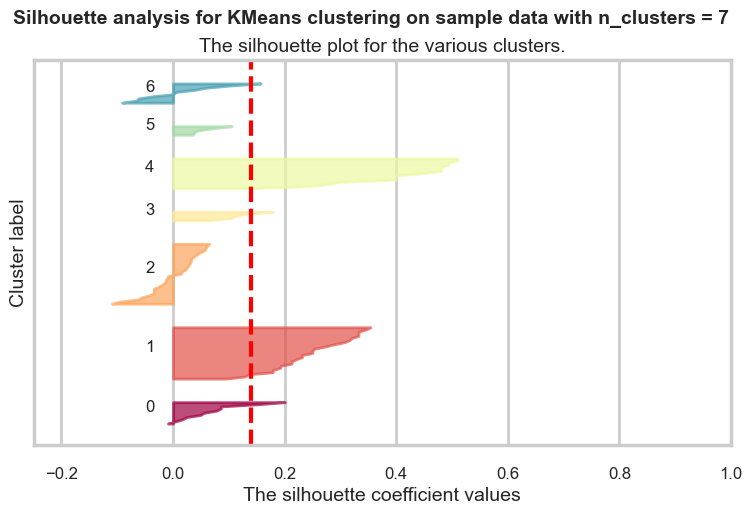

C:\Users\parva\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


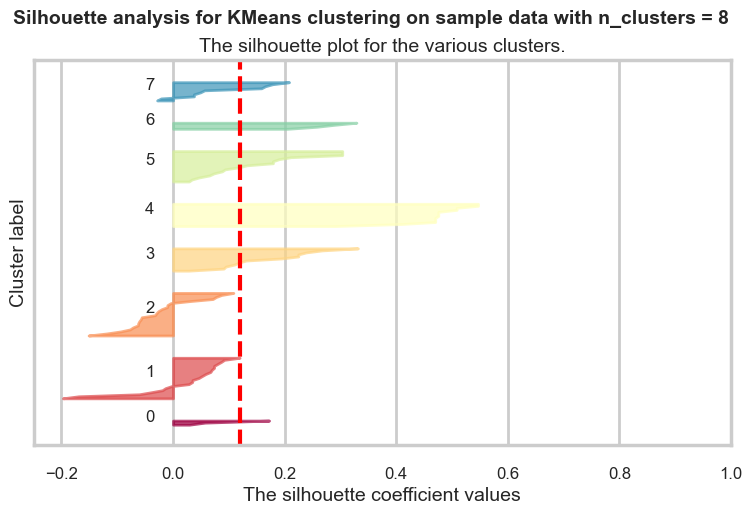

C:\Users\parva\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


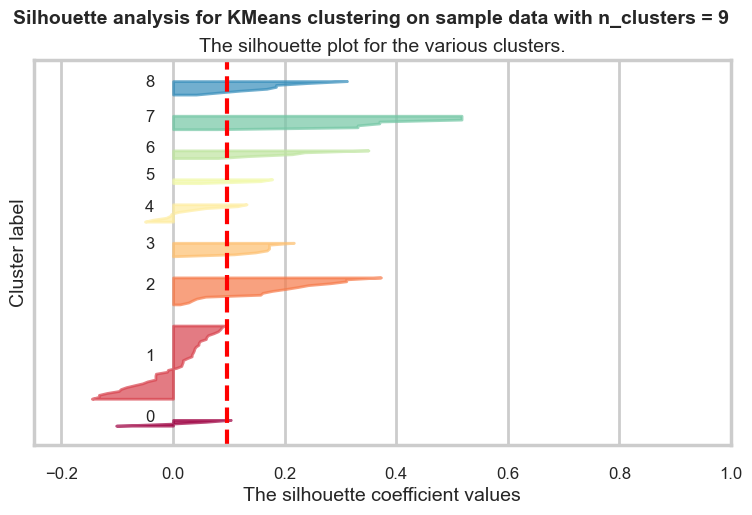

C:\Users\parva\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


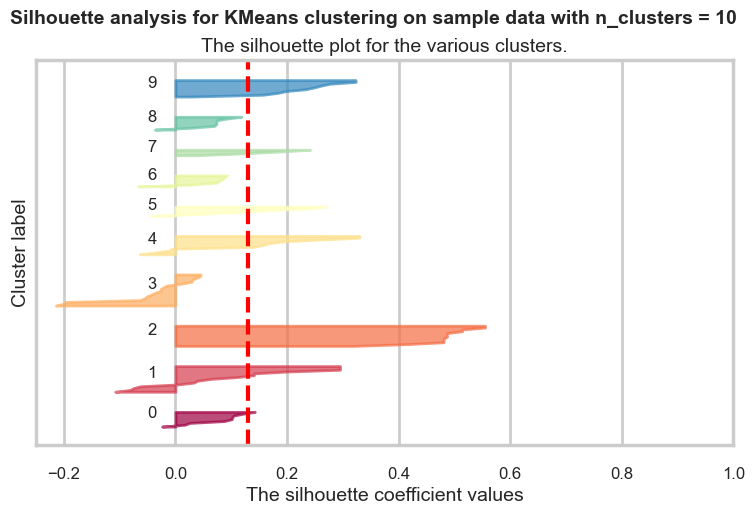

In [12]:
# Your turn.

import sklearn.metrics

# Make an empty list called avg_silhouette_scores
avg_silhouette_scores = []
cmap_spectral = plt.get_cmap("Spectral")   

# Iterate through Krange with variable K as before
for K in Krange:
    fig, ax1 = plt.subplots(1, 1)
    fig.set_size_inches(9, 5)

    # The 1st subplot is the silhouette plot
    # The silhouette coefficient can range from -1, 1
    # Call set_xlim on ax1
    ax1.set_xlim([-0.25, 1])
    # The (n_clusters+1)*10 is for inserting blank space between silhouette
    # plots of individual clusters, to demarcate them clearly.
    ax1.set_ylim([0, len(X) + (K + 1) * 10])

    # Initialize the clusterer with the SAME settings as the elbow section,
    # so both methods are judging the same clusterings.
    clusterer = sklearn.cluster.KMeans(n_clusters=K, random_state=SEED, n_init=10)
    cluster_labels = clusterer.fit_predict(X)

    # The silhouette_score gives the average value for all the samples.
    # Make a variable called silhouette_avg. Set the parameters to silhouette_score to X, and cluster_labels
    silhouette_avg = sklearn.metrics.silhouette_score(X, cluster_labels)
    avg_silhouette_scores.append(silhouette_avg)

    # Compute the silhouette scores for each sample
    # Call sklearn.metrics.silhouette_samples with the below parameters
    sample_silhouette_values = sklearn.metrics.silhouette_samples(X, cluster_labels)

    y_lower = 10
    for i in range(K):
        # Aggregate the silhouette scores for samples belonging to
        # cluster i, and sort them
        # Make a variable called ith_cluster_silhouette_values
        ith_cluster_silhouette_values = \
            sample_silhouette_values[cluster_labels == i]

        # Call sort() on this variable
        ith_cluster_silhouette_values.sort()

        # Call shape[0] on ith_cluster_silhouette_values
        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cmap_spectral(float(i) / K)
        ax1.fill_betweenx(np.arange(y_lower, y_upper),
                          0, ith_cluster_silhouette_values,
                          facecolor=color, edgecolor=color, alpha=0.7)

        # Label the silhouette plots with their cluster numbers at the middle
        # This requires calling text() on ax1
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontsize=12)

        # Compute the new y_lower for next plot
        y_lower = y_upper + 10  # 10 for the 0 samples

    # Setting title, xlabel and ylabel
    ax1.set_title("The silhouette plot for the various clusters.", fontsize=14)
    ax1.set_xlabel("The silhouette coefficient values", fontsize=14)
    ax1.set_ylabel("Cluster label", fontsize=14)

    # The vertical line for average silhouette score of all the values
    # This requires axvline()
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([])  # Clear the yaxis labels / ticks
    ax1.set_xticks([-0.2, 0, 0.2, 0.4, 0.6, 0.8, 1])
    ax1.tick_params(labelsize=12)

    plt.suptitle(("Silhouette analysis for KMeans clustering on sample data "
                  "with n_clusters = %d" % K),
                 fontsize=14, fontweight='bold')
    plt.show()

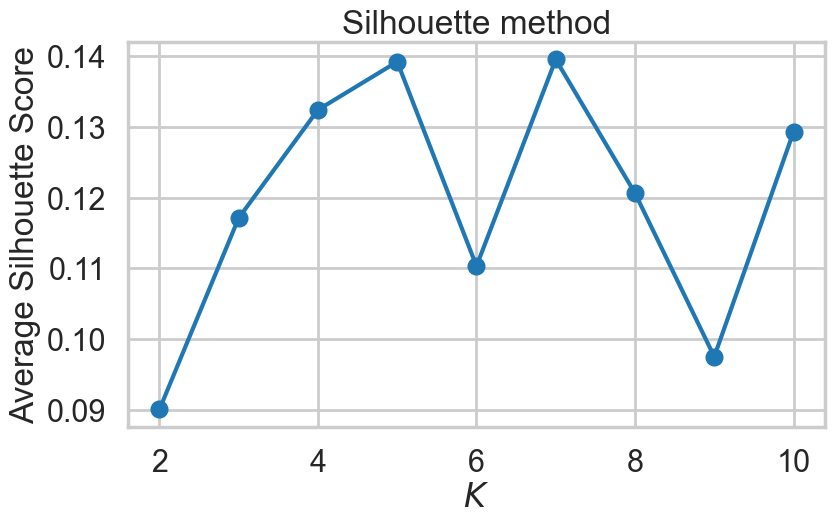

K,2,3,4,5,6,7,8,9,10
avg_silhouette,0.09,0.117,0.132,0.139,0.11,0.14,0.121,0.098,0.129


In [13]:
plt.figure(figsize=(9, 5))
plt.plot(Krange, avg_silhouette_scores, marker='o')
plt.xlabel("$K$")
plt.ylabel("Average Silhouette Score")
plt.title("Silhouette method")
plt.show()

pd.DataFrame({"K": Krange, "avg_silhouette": np.round(avg_silhouette_scores, 3)}).set_index("K").T

silhouette prefers K = 7 (or 5), the elbow says K = 3, and all scores are below 0.25, so there’s no strong structure.

#### 3aiii.  Choosing $K$: The Gap Statistic

There is one last method worth covering for picking $K$, the so-called Gap statistic. The computation for the gap statistic builds on the sum-of-squares established in the Elbow method discussion, and compares it to the sum-of-squares of a "null distribution," that is, a random set of points with no clustering. The estimate for the optimal number of clusters $K$ is the value for which $\log{SS}$ falls the farthest below that of the reference distribution:

$$G_k = E_n^*\{\log SS_k\} - \log SS_k$$

In other words a good clustering yields a much larger difference between the reference distribution and the clustered data. The reference distribution is a Monte Carlo (randomization) procedure that constructs $B$ random distributions of points within the bounding box (limits) of the original data and then applies K-means to this synthetic distribution of data points.. $E_n^*\{\log SS_k\}$ is just the average $SS_k$ over all $B$ replicates. We then compute the standard deviation $\sigma_{SS}$ of the values of $SS_k$ computed from the $B$ replicates of the reference distribution and compute

$$s_k = \sqrt{1+1/B}\sigma_{SS}$$

Finally, we choose $K=k$ such that $G_k \geq G_{k+1} - s_{k+1}$.

#### Aside: Choosing $K$ when we Have Labels

Unsupervised learning expects that we do not have the labels. In some situations, we may wish to cluster data that is labeled. Computing the optimal number of clusters is much easier if we have access to labels. There are several methods available. We will not go into the math or details since it is rare to have access to the labels, but we provide the names and references of these measures.

* Adjusted Rand Index
* Mutual Information
* V-Measure
* Fowlkes–Mallows index

**Hint:** See [this article](http://scikit-learn.org/stable/modules/clustering.html) for more information about these metrics.

### 3b. Visualizing Clusters using PCA

How do we visualize clusters? If we only had two features, we could likely plot the data as is. But we have 100 data points each containing 32 features (dimensions). Principal Component Analysis (PCA) will help us reduce the dimensionality of our data from 32 to something lower. For a visualization on the coordinate plane, we will use 2 dimensions. In this exercise, we're going to use it to transform our multi-dimensional dataset into a 2 dimensional dataset.

This is only one use of PCA for dimension reduction. We can also use PCA when we want to perform regression but we have a set of highly correlated variables. PCA untangles these correlations into a smaller number of features/predictors all of which are orthogonal (not correlated). PCA is also used to reduce a large set of variables into a much smaller one.

**Hint:** PCA was discussed in the previous subunit. If you need help with it, consult [this useful article](https://towardsdatascience.com/a-one-stop-shop-for-principal-component-analysis-5582fb7e0a9c) and [this visual explanation](http://setosa.io/ev/principal-component-analysis/). 

<div class="span5 alert alert-info">
<h3>Checkup Exercise Set IV</h3>

<p><b>Exercise:</b> Use PCA to plot your clusters:</p>

<ul>
<li> Use scikit-learn's [`PCA`](http://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) function to reduce the dimensionality of your clustering data to 2 components
<li> Create a data frame with the following fields:
  <ul>
  <li> customer name
  <li> cluster id the customer belongs to
  <li> the two PCA components (label them `x` and `y`)
  </ul>
<li> Plot a scatterplot of the `x` vs `y` columns
<li> Color-code points differently based on cluster ID
<li> How do the clusters look? 
<li> Based on what you see, what seems to be the best value for $K$? Moreover, which method of choosing $K$ seems to have produced the optimal result visually?
</ul>

<p><b>Exercise:</b> Now look at both the original raw data about the offers and transactions and look at the fitted clusters. Tell a story about the clusters in context of the original data. For example, do the clusters correspond to wine variants or something else interesting?</p>
</div>

C:\Users\parva\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


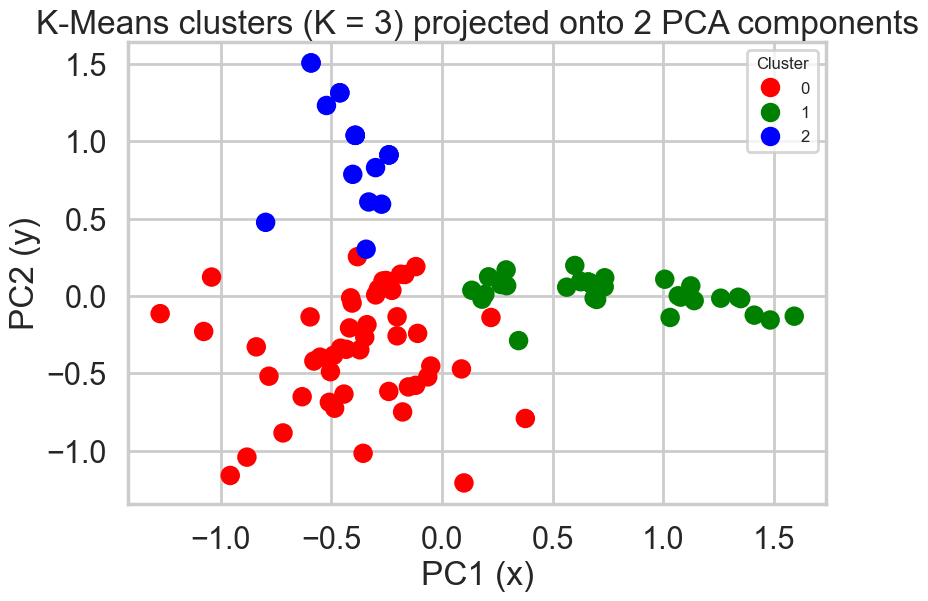

,customer_name,cluster,x,y
0,Adams,1,1.007580,0.108215
1,Allen,0,-0.287539,0.044715
2,Anderson,2,-0.392032,1.038391
3,Bailey,1,0.699477,-0.022542
4,Baker,0,0.088183,-0.471695


In [14]:
#your turn
import sklearn.decomposition
import matplotlib.colors

# Fit KMeans ONCE with best_K and reuse these assignments for every plot below,
# so cluster colours/IDs stay consistent between cells.
model = sklearn.cluster.KMeans(n_clusters=best_K, random_state=SEED, n_init=10)
# Call a fit_predict() on X
cluster_assignments = model.fit_predict(X)

# Let's visualiaze with colors.ListedColormap
colors = ['red', 'green', 'blue']
cmap = matplotlib.colors.ListedColormap(colors)

# We're going to do some PCA here. Call decomposition.PCA on sklearn, and pass n_components=2 as parameter
pca = sklearn.decomposition.PCA(n_components=2)
pcs = pca.fit_transform(X)

# Data frame with customer name, cluster id and the two PCA components (x, y)
df_pca = pd.DataFrame({
    "customer_name": pivoted.index,
    "cluster": cluster_assignments,
    "x": pcs[:, 0],
    "y": pcs[:, 1],
})

plt.figure(figsize=(9, 6))
scatter = plt.scatter(df_pca.x, df_pca.y, c=df_pca.cluster, cmap=cmap)
plt.xlabel("PC1 (x)")
plt.ylabel("PC2 (y)")
plt.title(f"K-Means clusters (K = {best_K}) projected onto 2 PCA components")
plt.legend(*scatter.legend_elements(), title="Cluster", fontsize=12, title_fontsize=12)
plt.show()

df_pca.head()

What we've done is we've taken those columns of 0/1 indicator variables, and we've transformed them into a 2-D dataset. We took one column and arbitrarily called it `x` and then called the other `y`. Now we can throw each point into a scatterplot. We color coded each point based on it's cluster so it's easier to see them.

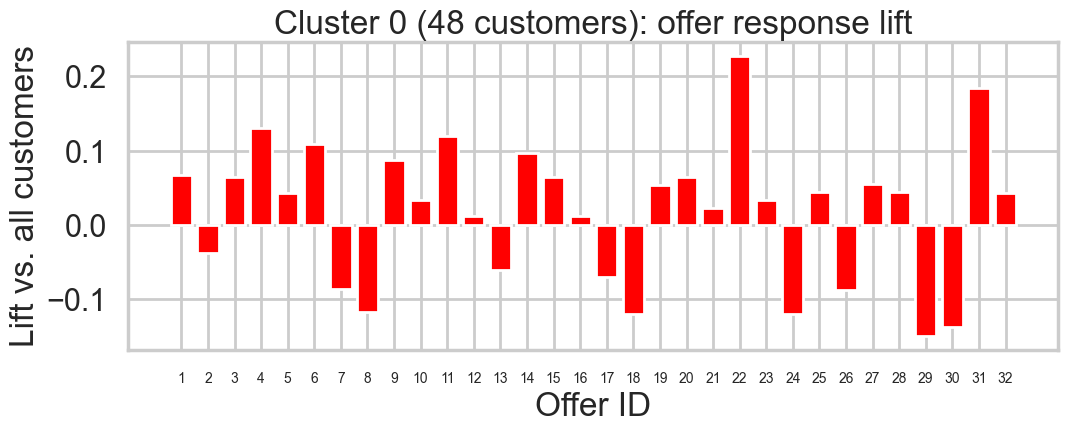

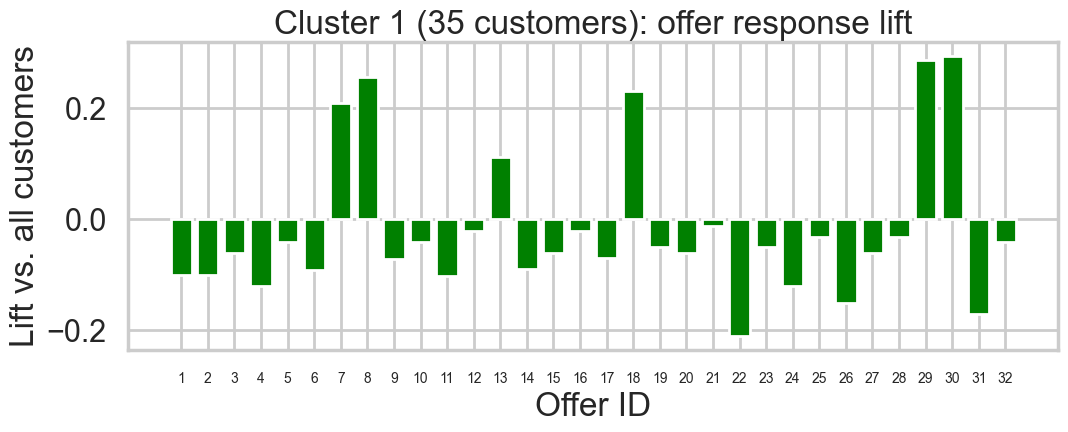

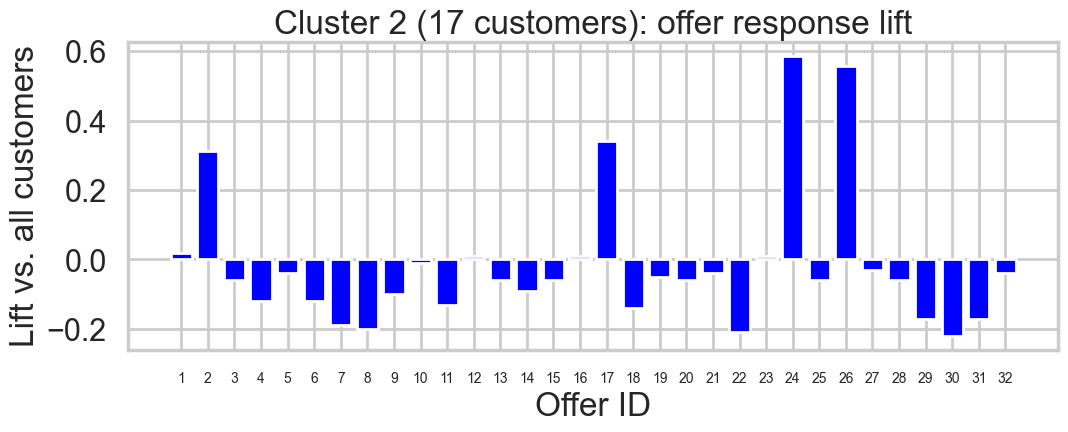

In [15]:
# Plot count of offer_id in each cluster.
# But, certain offers were used more than others in the original data.
# Let's compute the difference between how often they were used in each cluster vs globally.
# (Reuses cluster_assignments from the cell above -- no refit.)
n_customers = len(pivoted)
offer_proportions = pivoted.sum(axis=0) / n_customers
for i in range(best_K):
    plt.figure(figsize=(12, 4))
    cluster = pivoted[cluster_assignments == i]
    offer_proportions_cluster = cluster.sum(axis=0) / cluster.shape[0]  # Number of customers in cluster
    lift = offer_proportions_cluster - offer_proportions
    plt.bar(pivoted.columns, lift, color=colors[i])
    plt.xticks(pivoted.columns, fontsize=10)
    plt.xlabel("Offer ID")
    plt.ylabel("Lift vs. all customers")
    plt.title(f"Cluster {i} ({cluster.shape[0]} customers): offer response lift")
    plt.show()

In [16]:
merged_c = merged.copy()
merged_c["cluster"] = merged_c["customer_name"].map(dict(zip(pivoted.index, cluster_assignments)))

profile = merged_c.groupby("cluster").agg(
    customers=("customer_name", "nunique"),
    transactions=("offer_id", "size"),
    avg_min_qty=("min_qty", "mean"),
    avg_discount=("discount", "mean"),
    pct_past_peak=("past_peak", "mean"),
).round(2)
display(profile)

# Top 3 varietals (share of each cluster's transactions)
top_varietals = (merged_c.groupby("cluster")["varietal"]
                 .value_counts(normalize=True).round(2)
                 .groupby(level=0).head(3))
top_varietals

,customers,transactions,avg_min_qty,avg_discount,pct_past_peak
cluster,,,,,
0,48,186,79.13,62.91,0.22
1,35,93,13.35,56.52,0.17
2,17,45,65.87,51.42,0.00


cluster  varietal          
0        Champagne             0.41
         Cabernet Sauvignon    0.16
         Prosecco              0.13
1        Espumante             0.31
         Malbec                0.19
         Prosecco              0.18
2        Pinot Noir            0.84
         Malbec                0.04
         Prosecco              0.04
Name: proportion, dtype: float64

- **How do the clusters look?** The three clusters appear fairly well separated in the 2D PCA plot. Cluster 1 (green) spreads along PC1, cluster 2 (blue) extends along PC2, and cluster 0 (red) forms a looser group in the lower left. However, the two components explain only about 25% of the variance, so the plot may overstate the separation.

- **Best K / method:** K = 3 appears to be the best choice visually and agrees with the elbow method. The silhouette method suggests K = 7, but those clusters are less distinct in this plot.

- **What the clusters represent:** The groups differ mainly in grape variety and order size.
  - **Cluster 0: Bulk buyers looking for deals (48 customers).** They have the highest average minimum quantity (79 kg) and discount (63%). Their purchases are mainly Champagne (41%), Cabernet Sauvignon and Prosecco, mostly French wines.
  - **Cluster 1: Small-quantity buyers (35 customers).** Their average minimum quantity is 13 kg, compared with 58 kg overall. They favor casual wines such as Espumante, Malbec, Prosecco and Pinot Grigio.
  - **Cluster 2: Pinot Noir loyalists (17 customers).** Pinot Noir accounts for 84% of their purchases, and they never bought past-peak wine.

- **Marketing use:** Target cluster 0 with bulk and high-discount offers, cluster 1 with small-pack offers, and cluster 2 with Pinot Noir promotions.

<div class="span5 alert alert-info">
<h3>Exercise Set V</h3>

<p>As we saw earlier, PCA has a lot of other uses. Since we wanted to visualize our data in 2 dimensions, restricted the number of dimensions to 2 in PCA. But what is the true optimal number of dimensions?</p>

<p><b>Exercise:</b> Using a new PCA object shown in the next cell, plot the `explained_variance_` field and look for the elbow point, the point where the curve's rate of descent seems to slow sharply. This value is one possible value for the optimal number of dimensions. What is it?</p>
</div>

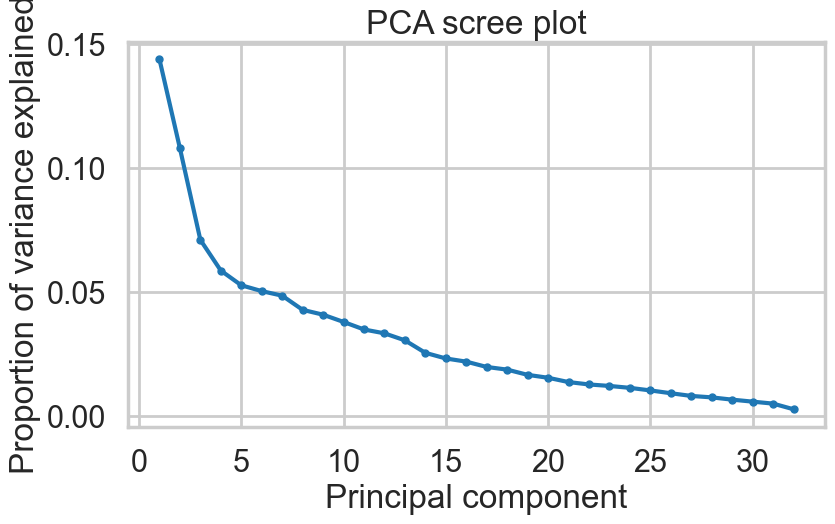

component,1,2,3,4,5,6,7,8
variance_ratio,0.144,0.108,0.071,0.059,0.053,0.050,0.049,0.043
cumulative,0.144,0.252,0.323,0.382,0.434,0.485,0.533,0.576


In [17]:
#your turn
import sklearn.decomposition
pca = sklearn.decomposition.PCA()
pca.fit(X)

# Do the rest on your own :)
# explained_variance_ratio_ is explained_variance_ divided by the total, so the curve has the same shape
variance = pca.explained_variance_ratio_
components = range(1, len(variance) + 1)   # component numbers start at 1, not 0

# Plot() it
plt.figure(figsize=(9, 5))
plt.plot(components, variance, marker='o', markersize=5)

# Label the axes
plt.xlabel("Principal component")
plt.ylabel("Proportion of variance explained")
plt.title("PCA scree plot")
plt.show()

pd.DataFrame({"component": components,
              "variance_ratio": variance.round(3),
              "cumulative": variance.cumsum().round(3)}).head(8).set_index("component").T

The explained variance falls steeply over the first three components (14.4% to 10.8% to 7.1%) and then flattens (5.9%, 5.3%, 5.0%, …). The elbow is at about **3 components**. Those 3 still explain only about 32% of the variance (half needs about 7 components), so the purchase data are high-dimensional and noisy. The 2-D plot is a rough view, not a faithful one.

## 4. Conclusions and next steps
### 4a. Conclusions
What can you conclude from your investigations? Make a note, formulate it as clearly as possible, and be prepared to discuss it with your mentor in your next call. 

- Turning 324 transactions into a 100 × 32 customer-by-offer 0/1 matrix and running K-Means gives three customer segments: bulk Champagne and deal buyers (48), small-quantity casual buyers (35) and Pinot Noir loyalists (17).
- The elbow method, the PCA view and the near-perfect agreement between K-Means and Ward clustering (ARI 0.96) support K = 3. The silhouette method prefers K = 7 (or 5), but its scores differ very little between K values.
- The structure is weak: all silhouette scores are below 0.15, because each customer responded to only about 3 of 32 offers. Treat the segments as tendencies, not hard boundaries.

### 4b. Other clustering algorithms

k-means is only one of a ton of clustering algorithms. Below is a brief description of several clustering algorithms, and the table provides references to the other clustering algorithms in scikit-learn. 

* **Affinity Propagation** does not require the number of clusters $K$ to be known in advance! AP uses a "message passing" paradigm to cluster points based on their similarity. 

* **Spectral Clustering** uses the eigenvalues of a similarity matrix to reduce the dimensionality of the data before clustering in a lower dimensional space. This is tangentially similar to what we did to visualize k-means clusters using PCA. The number of clusters must be known a priori.

* **Ward's Method** applies to hierarchical clustering. Hierarchical clustering algorithms take a set of data and successively divide the observations into more and more clusters at each layer of the hierarchy. Ward's method is used to determine when two clusters in the hierarchy should be combined into one. It is basically an extension of hierarchical clustering. Hierarchical clustering is *divisive*, that is, all observations are part of the same cluster at first, and at each successive iteration, the clusters are made smaller and smaller. With hierarchical clustering, a hierarchy is constructed, and there is not really the concept of "number of clusters." The number of clusters simply determines how low or how high in the hierarchy we reference and can be determined empirically or by looking at the [dendogram](https://docs.scipy.org/doc/scipy-0.18.1/reference/generated/scipy.cluster.hierarchy.dendrogram.html).

* **Agglomerative Clustering** is similar to hierarchical clustering but but is not divisive, it is *agglomerative*. That is, every observation is placed into its own cluster and at each iteration or level or the hierarchy, observations are merged into fewer and fewer clusters until convergence. Similar to hierarchical clustering, the constructed hierarchy contains all possible numbers of clusters and it is up to the analyst to pick the number by reviewing statistics or the dendogram.

* **DBSCAN** is based on point density rather than distance. It groups together points with many nearby neighbors. DBSCAN is one of the most cited algorithms in the literature. It does not require knowing the number of clusters a priori, but does require specifying the neighborhood size.

### Clustering Algorithms in Scikit-learn
<table border="1">
<colgroup>
<col width="15%" />
<col width="16%" />
<col width="20%" />
<col width="27%" />
<col width="22%" />
</colgroup>
<thead valign="bottom">
<tr><th>Method name</th>
<th>Parameters</th>
<th>Scalability</th>
<th>Use Case</th>
<th>Geometry (metric used)</th>
</tr>
</thead>
<tbody valign="top">
<tr><td>K-Means</span></a></td>
<td>number of clusters</td>
<td>Very large<span class="pre">n_samples</span>, medium <span class="pre">n_clusters</span> with
MiniBatch code</td>
<td>General-purpose, even cluster size, flat geometry, not too many clusters</td>
<td>Distances between points</td>
</tr>
<tr><td>Affinity propagation</td>
<td>damping, sample preference</td>
<td>Not scalable with n_samples</td>
<td>Many clusters, uneven cluster size, non-flat geometry</td>
<td>Graph distance (e.g. nearest-neighbor graph)</td>
</tr>
<tr><td>Mean-shift</td>
<td>bandwidth</td>
<td>Not scalable with <span class="pre">n_samples</span></td>
<td>Many clusters, uneven cluster size, non-flat geometry</td>
<td>Distances between points</td>
</tr>
<tr><td>Spectral clustering</td>
<td>number of clusters</td>
<td>Medium <span class="pre">n_samples</span>, small <span class="pre">n_clusters</span></td>
<td>Few clusters, even cluster size, non-flat geometry</td>
<td>Graph distance (e.g. nearest-neighbor graph)</td>
</tr>
<tr><td>Ward hierarchical clustering</td>
<td>number of clusters</td>
<td>Large <span class="pre">n_samples</span> and <span class="pre">n_clusters</span></td>
<td>Many clusters, possibly connectivity constraints</td>
<td>Distances between points</td>
</tr>
<tr><td>Agglomerative clustering</td>
<td>number of clusters, linkage type, distance</td>
<td>Large <span class="pre">n_samples</span> and <span class="pre">n_clusters</span></td>
<td>Many clusters, possibly connectivity constraints, non Euclidean
distances</td>
<td>Any pairwise distance</td>
</tr>
<tr><td>DBSCAN</td>
<td>neighborhood size</td>
<td>Very large <span class="pre">n_samples</span>, medium <span class="pre">n_clusters</span></td>
<td>Non-flat geometry, uneven cluster sizes</td>
<td>Distances between nearest points</td>
</tr>
<tr><td>Gaussian mixtures</td>
<td>many</td>
<td>Not scalable</td>
<td>Flat geometry, good for density estimation</td>
<td>Mahalanobis distances to  centers</td>
</tr>
<tr><td>Birch</td>
<td>branching factor, threshold, optional global clusterer.</td>
<td>Large <span class="pre">n_clusters</span> and <span class="pre">n_samples</span></td>
<td>Large dataset, outlier removal, data reduction.</td>
<td>Euclidean distance between points</td>
</tr>
</tbody>
</table>
Source: http://scikit-learn.org/stable/modules/clustering.html

<div class="span5 alert alert-info">
<h3>Exercise Set VI</h3>

<p><b>Exercise:</b> Try clustering using the following algorithms. </p>
<ol>
<li>Affinity propagation
<li>Spectral clustering
<li>Agglomerative clustering
<li>DBSCAN
</ol>
<p>How do their results compare? Which performs the best? Tell a story why you think it performs the best.</p>
</div>


In [18]:
# Your turn
from sklearn.cluster import AffinityPropagation, SpectralClustering, AgglomerativeClustering, DBSCAN
from sklearn.metrics import adjusted_rand_score

# The data are 0/1 purchase indicators, so Jaccard distance (shared purchases / any purchases)
# is a natural similarity for the density-based method.
models = {
    "K-Means (K=3)":            cluster_assignments,
    "Affinity Propagation":     AffinityPropagation(random_state=SEED).fit_predict(X),
    "Spectral (K=3)":           SpectralClustering(n_clusters=3, affinity="nearest_neighbors",
                                                   n_neighbors=10, random_state=SEED).fit_predict(X),
    "Agglomerative Ward (K=3)": AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X),
    "DBSCAN (Jaccard, eps=0.5)": DBSCAN(eps=0.5, min_samples=3, metric="jaccard").fit_predict(X.astype(bool)),
}

rows = []
for name, labels in models.items():
    labels = np.asarray(labels)
    n_clusters = len(set(labels) - {-1})
    noise = int((labels == -1).sum())
    sizes = sorted(np.bincount(labels[labels >= 0]).tolist(), reverse=True)
    keep = labels >= 0   # DBSCAN marks noise as -1; score only the clustered points
    sil = sklearn.metrics.silhouette_score(X[keep], labels[keep]) if n_clusters > 1 else np.nan
    rows.append({"method": name, "n_clusters": n_clusters, "noise_points": noise,
                 "cluster_sizes": sizes, "silhouette (excl. noise)": round(sil, 3),
                 "ARI_vs_KMeans": round(adjusted_rand_score(cluster_assignments, labels), 2)})

comparison = pd.DataFrame(rows).set_index("method")
comparison

C:\Users\parva\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,n_clusters,noise_points,cluster_sizes,silhouette (excl. noise),ARI_vs_KMeans
method,,,,,
K-Means (K=3),3,0,"[48, 35, 17]",0.117,1.00
Affinity Propagation,14,0,"[11, 11, 10, 10, 10, 8, 8, 7, 6, 5, 5, 3, 3, 3]",0.129,0.16
Spectral (K=3),3,0,"[55, 29, 16]",0.115,0.72
Agglomerative Ward (K=3),3,0,"[49, 34, 17]",0.116,0.96
"DBSCAN (Jaccard, eps=0.5)",6,33,"[30, 14, 7, 7, 5, 4]",0.220,0.45


- Agglomerative (Ward): almost identical to K-Means (ARI 0.96, sizes 49/34/17). Ward minimises the same within-cluster sum of squares.
- Spectral: similar (ARI 0.72). It finds the same Pinot Noir group but merges more customers into one cluster of 55.
- Affinity Propagation: picks 14 small clusters of 3–11 customers. Its silhouette is slightly higher (0.129), but the result is too fragmented to be useful.
- DBSCAN: labels 33 customers as noise. Its 0.22 silhouette is scored on only the 67 clustered points, so it isn’t comparable to the others.
- Best: K-Means with K = 3 (or Ward). Two different algorithms find the same three groups, which suggests the segments are real. The groups are also balanced and easy to interpret. No method does dramatically better, because the data are sparse.